# Лабораторная работа № 3 — Регрессионный анализ

Цель: изучить алгоритмы регрессии на практике. Часть 1 — парная линейная регрессия; часть 2 — полиномиальная; часть 3 — прогнозирование годовой зарплаты линейной регрессией, kNN и деревом решений.

### Подготовка библиотек и вспомогательных функций

**pandas и NumPy** используются для работы с данными, **matplotlib и seaborn** для графиков, классы моделей, преобразователи и метрики из **scikit-learn**.
`SEED = 42` нужен для воспроизводимости случайных операций, папка `results` - для результатов.
`save(name)` необходим для сохранения графиков, `metrics(y, pred)` для расчёта MSE, MAE, RMSE и R², а `table_image(...)` — для сохранения готовой таблицы как изображения.




In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
OUT = Path('results'); OUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 115, 'axes.titlesize': 12})
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 160)

def save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=170, bbox_inches='tight')
    plt.show()

def metrics(y, pred):
    return {'MSE': mean_squared_error(y, pred),
            'MAE': mean_absolute_error(y, pred),
            'RMSE': np.sqrt(mean_squared_error(y, pred)),
            'R2': r2_score(y, pred)}

def table_image(frame, name, index=True):
    view = frame.copy()
    for c in view.select_dtypes(include='number'):
        view[c] = view[c].map(lambda v: (f'{v:.3e}' if c == 'MSE' else f'{v:,.4f}') if isinstance(v, (float, np.floating)) else str(v))
    fig, ax = plt.subplots(figsize=(8, max(1.5, .34 * (len(view) + 1))))
    ax.axis('off')
    t = ax.table(cellText=view.values, colLabels=view.columns,
                 rowLabels=view.index if index else None, loc='center', cellLoc='center')
    t.auto_set_font_size(False); t.set_fontsize(11); t.scale(1, 1.5)
    for (r, c), cell in t.get_celld().items():
        cell.set_edgecolor('#cccccc')
        if r == 0: cell.set_facecolor('#dce6f1')
    save(name)

## 1 Простая линейная регрессия
### 1.1 Загрузка и описание данных
Для варианта 6 используется лист `var6`. Коэффициент Пирсона характеризует линейную связь; небольшая корреляция не исключает нелинейной зависимости.

### Формулы описательной статистики и корреляции

Для одного числового столбца x обозначим через n число непустых значений, xᵢ — i-е наблюдение, x̄ — среднее. В describe() стандартное отклонение является выборочным, с делителем n − 1.

$$
\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i;\quad s_x=\sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2}
$$

Квартили в pandas вычисляются линейной интерполяцией. Пусть x₍₀₎,…,x₍ₙ₋₁₎ — значения по возрастанию с индексацией от нуля, p — уровень квантиля. Если h целое, квантиль равен x₍ₕ₎; в остальных случаях:

$$
h=(n-1)p;\quad j=\lfloor h\rfloor;\quad g=h-j;\quad Q_p=(1-g)x_{(j)}+g x_{(j+1)}
$$

Медиана равна Q₀․₅, первый и третий квартили — Q₀․₂₅ и Q₀․₇₅. В describe() также выводятся count = n, min и max. Коэффициент Пирсона для двух непостоянных столбцов на общих непустых строках:

$$
r_{xy}=\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2\sum_{i=1}^{n}(y_i-\bar{y})^2}}
$$

Значения r находятся от −1 до 1; коэффициент измеряет линейную связь. Для постоянного столбца знаменатель равен нулю и корреляция не определена. Эти описательные формулы применяются и к salary.csv.


Размер: (1000, 3) Пропуски: 0 Дубликаты: 0


,x1,x2,y
0,-1.146666,-0.688365,-1.387058
1,-0.060865,1.590076,1.879463
2,0.910263,-1.847089,0.455931
3,-0.293059,-1.514869,-2.048716
4,0.096293,-0.193451,0.002519
5,0.190723,-0.176330,-0.016764
6,1.095304,-0.817547,0.815261
7,-0.040736,-0.618264,-1.288215
8,0.476731,0.406197,0.649145
9,-1.643971,-1.854943,-4.389140


,x1,x2,y
count,1000.000000,1000.000000,1000.000000
mean,0.000004,0.000018,-0.007679
std,1.155243,1.155356,1.925932
min,-1.999033,-1.996413,-5.667686
25%,-0.999680,-0.997221,-1.377376
50%,-0.000644,0.000012,-0.025591
75%,0.998839,0.999964,1.345011
max,1.996395,1.997690,5.520120


,x1,x2,y
x1,1.000000,-0.003132,0.770348
x2,-0.003132,1.000000,0.505821
y,0.770348,0.505821,1.000000


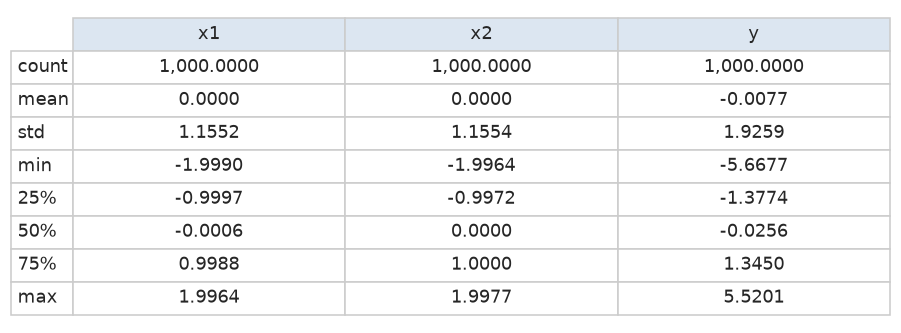

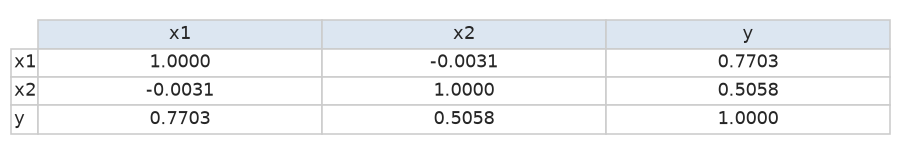

In [2]:
df = pd.read_excel('regression.xlsx', sheet_name='var6')
print('Размер:', df.shape, 'Пропуски:', df.isna().sum().sum(), 'Дубликаты:', df.duplicated().sum())
display(df.head(10))
display(df.describe())
display(df.corr(method='pearson'))
table_image(df.describe().round(4), '01_describe')
table_image(df.corr().round(4), '02_corr')

Пирсон: r(x1, y) ≈ 0,7703 — достаточно сильная положительная связь; r(x2, y) ≈ 0,5058 — умеренная положительная связь. Между x1 и x2 практически нет линейной связи (r ≈ −0,0031). Эти значения являются описанием всей исходной таблицы, а модели далее обучаются только на train.

### Формулы парной регрессии и обучения

Далее nₜᵣ — число строк обучающей выборки. Все средние и коэффициенты в формулах обучения вычисляются только по train. Для одного непостоянного признака метод наименьших квадратов даёт:

$$
\hat{y}_i=a x_i+b;\quad a=\frac{\sum_{i=1}^{n_{tr}}(x_i-\bar{x}_{tr})(y_i-\bar{y}_{tr})}{\sum_{i=1}^{n_{tr}}(x_i-\bar{x}_{tr})^2};\quad b=\bar{y}_{tr}-a\bar{x}_{tr}
$$

$$
(a,b)=\operatorname{argmin}_{a,b}\sum_{i=1}^{n_{tr}}(y_i-a x_i-b)^2
$$

Это соответствует LinearRegression с intercept. При нескольких признаках применяется та же минимизация по всем коэффициентам. Деление 80/20 в train_test_split с вещественным test_size = 0,2 задаёт размеры:

$$
n_{test}=\lceil 0.2N\rceil;\quad n_{train}=N-n_{test}
$$

N — число строк перед разделением; random_state = 42 фиксирует случайное перемешивание. Для первой части N = 1000, поэтому размеры равны 800 и 200.


Train: 800 Test: 200
x1 Все прогнозы тестовой выборки:


,x,y_true,y_pred,pred_minus_true
10,1.744757,2.181117,2.301535,0.120418
23,0.797144,0.624798,1.059551,0.434753
25,0.129604,1.474970,0.184643,-1.290326
30,1.248407,1.460704,1.650996,0.190292
39,1.340275,1.094289,1.771403,0.677115
44,-0.612170,-1.466353,-0.787559,0.678794
54,-0.618237,-0.633006,-0.795511,-0.162505
55,-0.398945,-0.212351,-0.508097,-0.295746
59,0.393715,1.119859,0.530799,-0.589061
60,0.322072,0.561065,0.436900,-0.124165


x2 Все прогнозы тестовой выборки:


,x,y_true,y_pred,pred_minus_true
10,0.315449,2.181117,0.239654,-1.941462
23,0.451592,0.624798,0.358680,-0.266118
25,1.723229,1.474970,1.470440,-0.004530
30,-0.017242,1.460704,-0.051209,-1.511913
39,-0.451366,1.094289,-0.430752,-1.525041
44,-1.224545,-1.466353,-1.106723,0.359630
54,0.774815,-0.633006,0.641266,1.274272
55,-0.281142,-0.212351,-0.281930,-0.069579
59,0.566391,1.119859,0.459046,-0.660813
60,1.190304,0.561065,1.004517,0.443452


,a,b,MSE,MAE,RMSE,R2
Признак,,,,,,
x1,1.310645,0.014778,1.560043,0.949193,1.249017,0.542221
x2,0.874274,-0.036135,2.743822,1.379719,1.656449,0.194854


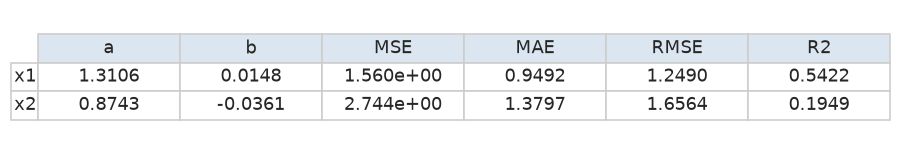

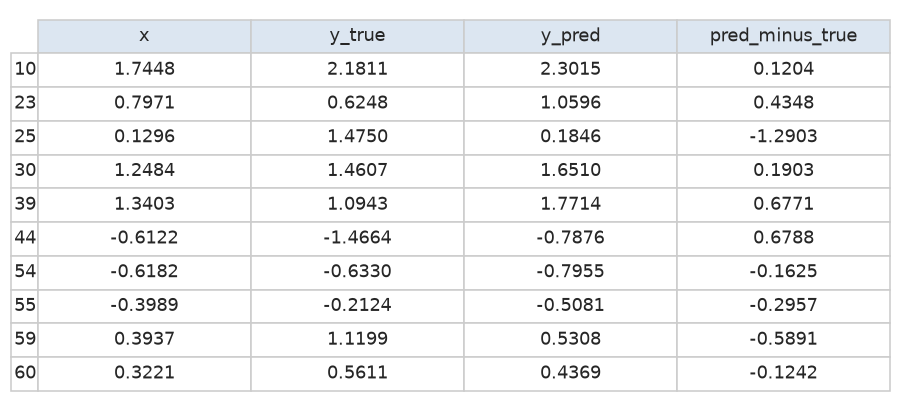

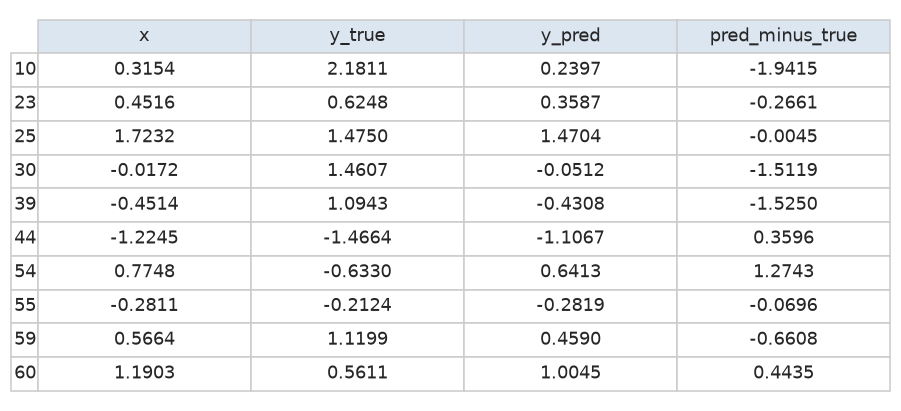

In [3]:
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=SEED)
train, test = df.loc[train_idx], df.loc[test_idx]
print('Train:', len(train), 'Test:', len(test))
linear_models, linear_rows, prediction_tables = {}, [], {}
for feature in ['x1', 'x2']:
    model = LinearRegression().fit(train[[feature]], train['y'])
    linear_models[feature] = model
    pred = model.predict(test[[feature]])
    linear_rows.append({'Признак': feature, 'a': model.coef_[0], 'b': model.intercept_,
                        **metrics(test['y'], pred)})
    result = pd.DataFrame({'x': test[feature], 'y_true': test['y'], 'y_pred': pred,
                           'pred_minus_true': pred - test['y']}).sort_index()
    prediction_tables[feature] = result
    result.to_csv(OUT / f'predictions_{feature}.csv', index_label='row')
    print(feature, 'Все прогнозы тестовой выборки:')
    with pd.option_context('display.max_rows', None): display(result)
linear_metrics = pd.DataFrame(linear_rows).set_index('Признак')
display(linear_metrics)
linear_metrics.to_csv(OUT / 'linear_metrics.csv')
table_image(linear_metrics, '03_linear_metrics')
table_image(prediction_tables['x1'].head(10), '04_predictions_x1')
table_image(prediction_tables['x2'].head(10), '05_predictions_x2')

### 1.2 Визуализация и метрики
MSE — средний квадрат ошибки, RMSE — его корень, MAE — средний модуль ошибки. MAE и RMSE выражены в единицах y, MSE — в квадратных единицах. R² сравнивает модель с прогнозом средним значением целевой переменной на оцениваемой выборке: чем ближе к 1, тем лучше; возможны отрицательные значения.

Остаток здесь определён как **прогноз минус факт**. На диаграммах факт–прогноз красная прямая y = x показывает идеальное совпадение; масштабы обеих осей одинаковы.

### Формулы ошибок и метрик качества

Пусть n — размер именно оцениваемой выборки, yᵢ — факт, ŷᵢ — прогноз. В коде и на графиках принят знак ошибки «прогноз − факт». Среднее для R² берётся по фактическим значениям этой же оцениваемой выборки:

$$
e_i=\hat{y}_i-y_i;\quad \bar{y}=\frac{1}{n}\sum_{i=1}^{n}y_i
$$

$$
\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^{n}e_i^2;\quad \mathrm{RMSE}=\sqrt{\mathrm{MSE}}
$$

$$
\mathrm{MAE}=\frac{1}{n}\sum_{i=1}^{n}|e_i|;\quad R^2=1-\frac{\sum_{i=1}^{n}e_i^2}{\sum_{i=1}^{n}(y_i-\bar{y})^2}
$$

Формула R² приведена для непостоянной цели. Отрицательное значение означает, что сумма квадратов ошибок модели больше, чем у константы ȳ оцениваемой выборки. Такая константа используется как знаменатель метрики; DummyRegressor обучается отдельно на среднем train. MSE имеет квадратные единицы y, MAE и RMSE — единицы y. На диаграмме факт–прогноз идеальная линия задаётся ŷ = y, на графике ошибок — e = 0. Те же формулы используются для train, test, центрального и полного тестов зарплаты; меняется только набор оцениваемых строк.


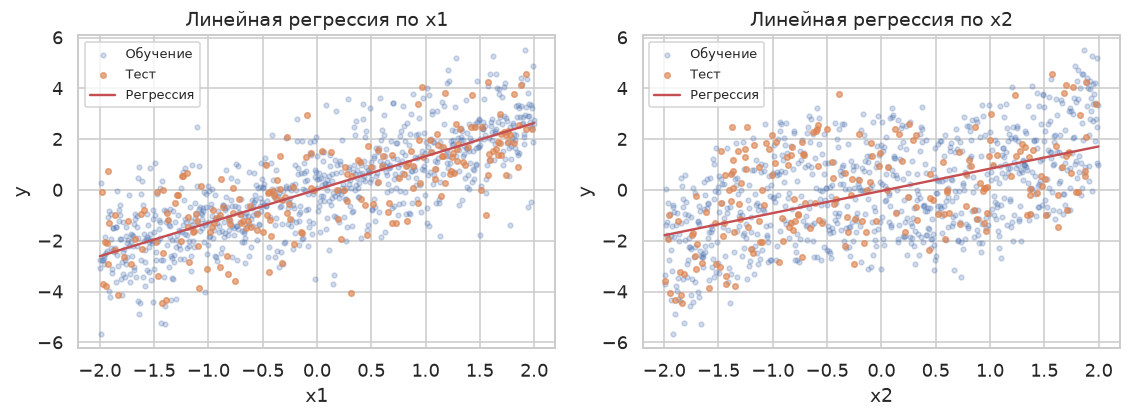

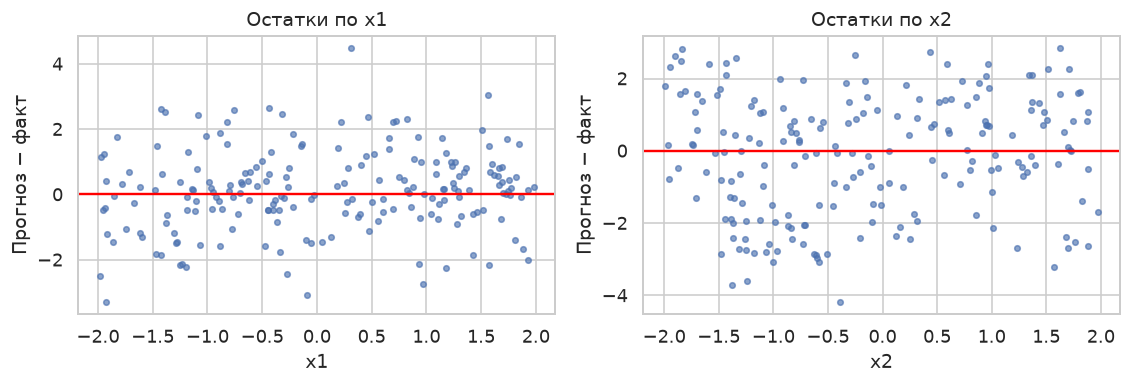

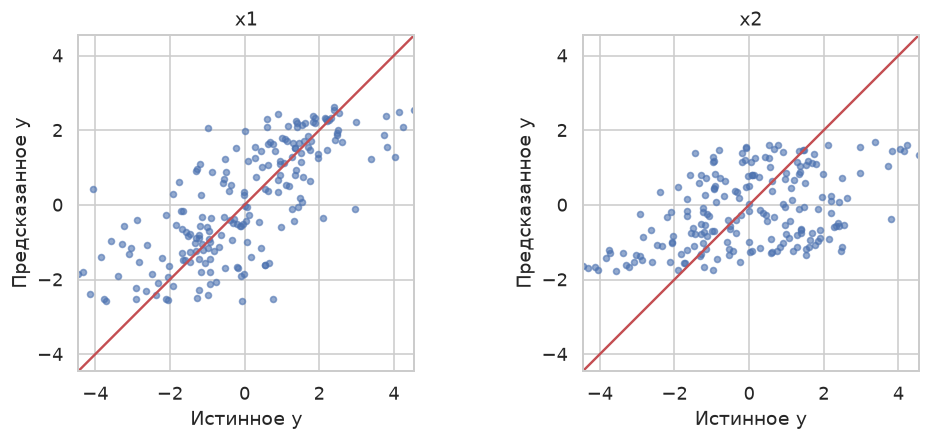

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, feature in zip(axes, ['x1', 'x2']):
    grid = pd.DataFrame({feature: np.linspace(df[feature].min(), df[feature].max(), 400)})
    ax.scatter(train[feature], train.y, s=9, alpha=.25, label='Обучение')
    ax.scatter(test[feature], test.y, s=12, alpha=.65, label='Тест')
    ax.plot(grid[feature], linear_models[feature].predict(grid), 'r', label='Регрессия')
    ax.set(xlabel=feature, ylabel='y', title=f'Линейная регрессия по {feature}'); ax.legend(fontsize=8)
save('06_linear_lines')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, feature in zip(axes, ['x1', 'x2']):
    t = prediction_tables[feature]
    ax.scatter(t.x, t.pred_minus_true, s=12, alpha=.65)
    ax.axhline(0, color='red'); ax.set(xlabel=feature, ylabel='Прогноз − факт', title=f'Остатки по {feature}')
save('07_linear_residuals')
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, feature in zip(axes, ['x1', 'x2']):
    t = prediction_tables[feature]; lo = min(t.y_true.min(), t.y_pred.min()); hi = max(t.y_true.max(), t.y_pred.max())
    ax.scatter(t.y_true, t.y_pred, s=14, alpha=.6); ax.plot([lo, hi], [lo, hi], 'r')
    ax.set(xlabel='Истинное y', ylabel='Предсказанное y', title=feature, xlim=(lo,hi), ylim=(lo,hi)); ax.set_aspect('equal')
save('08_linear_actual')

По тестовым метрикам модель x1 лучше модели x2. Но даже она не объясняет всю вариацию y: другая переменная и шум остаются за пределами парной модели. На графике x2 виден изгиб, а остатки меняются систематически, поэтому для полиномиальной части выбирается x2. Нельзя переносить вывод из варианта 1 о квадратичной зависимости x1 на вариант 6.

## 2 Полиномиальная регрессия
Для x2 сравниваются степени 1, 2, 3, 6 и 12. Используется PolynomialFeatures, затем StandardScaler и LinearRegression. Все преобразования обучаются внутри Pipeline.

Сложность выбирается по пятиблочной кросс-валидации **только на train**. Среди моделей, чей средний CV R² находится в пределах одной стандартной ошибки от максимума, выбирается наименьшая степень. Тестовые показатели используются для окончательной оценки, а не для настройки.

### Формулы полинома и выбора степени

Для степени d преобразователь PolynomialFeatures(include_bias=False) создаёт d столбцов. StandardScaler масштабирует каждый столбец по параметрам соответствующего train; свободный член добавляет LinearRegression:

$$
\phi_j(x)=x^j;\quad z_j=\frac{x^j-\mu_j}{s_j};\quad \hat{y}=b+\sum_{j=1}^{d}w_j z_j
$$

Здесь j = 1,…,d; μⱼ и sⱼ — среднее и стандартное отклонение степенного столбца с делителем nₜᵣ. После раскрытия скобок это обычный полином по исходному x:

$$
\hat{y}=\beta_0+\sum_{j=1}^{d}\beta_j x^j;\quad \beta_j=\frac{w_j}{s_j};\quad \beta_0=b-\sum_{j=1}^{d}\frac{w_j\mu_j}{s_j}
$$

В этой работе x = x2, d ∈ {1, 2, 3, 6, 12}. При пятиблочной кросс-валидации R²ₖ(d) — метрика на валидационном блоке k; модель и все преобразования обучаются на остальных четырёх блоках. Среднее качество и стандартная ошибка:

$$
\bar{R}^2(d)=\frac{1}{K}\sum_{k=1}^{K}R_k^2(d);\quad K=5
$$

$$
s_R(d)=\sqrt{\frac{1}{K-1}\sum_{k=1}^{K}(R_k^2(d)-\bar{R}^2(d))^2};\quad SE(d)=\frac{s_R(d)}{\sqrt{K}}
$$

$$
d_*=\operatorname{argmax}_{d}\bar{R}^2(d);\quad T=\bar{R}^2(d_*)-SE(d_*)
$$

$$
d_{chosen}=\min\{d:\bar{R}^2(d)\geq T\}
$$

Это ровно правило одной стандартной ошибки в коде: используется SE модели с максимальным средним CV R², затем выбирается минимальная допустимая степень. Стандартная ошибка служит эвристикой выбора сложности, а не гарантированным доверительным интервалом. Тестовые метрики не входят в этот критерий.


Выбранная степень по правилу одной стандартной ошибки: 3


,CV_R2,CV_SE,R2_train,R2_test,MAE_train,MAE_test
degree,,,,,,
1,0.254458,0.010800,0.268906,0.194854,1.396671,1.379719
2,0.254490,0.009993,0.270270,0.184440,1.394819,1.389230
3,0.308568,0.015821,0.328482,0.283506,1.348642,1.328753
6,0.304323,0.015812,0.332441,0.281144,1.340243,1.331663
12,0.296471,0.021901,0.337133,0.282372,1.335656,1.323929


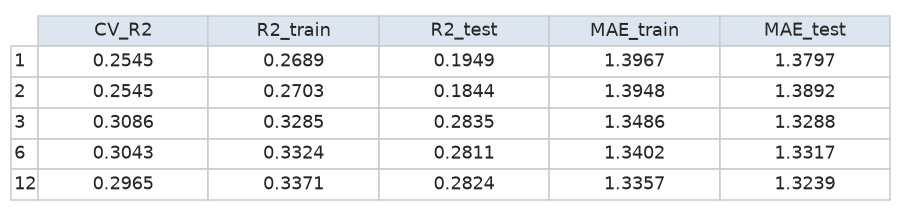

,y_true,y_pred,pred_minus_true
10,2.181117,-0.095174,-2.276291
23,0.624798,-0.074878,-0.699676
25,1.474970,1.926309,0.451339
30,1.460704,-0.091615,-1.552319
39,1.094289,-0.089434,-1.183722
...,...,...,...
985,-1.225392,-0.089231,1.136161
986,-0.040580,0.212391,0.252971
989,-1.204431,-2.320868,-1.116437
995,0.013087,-0.963091,-0.976178


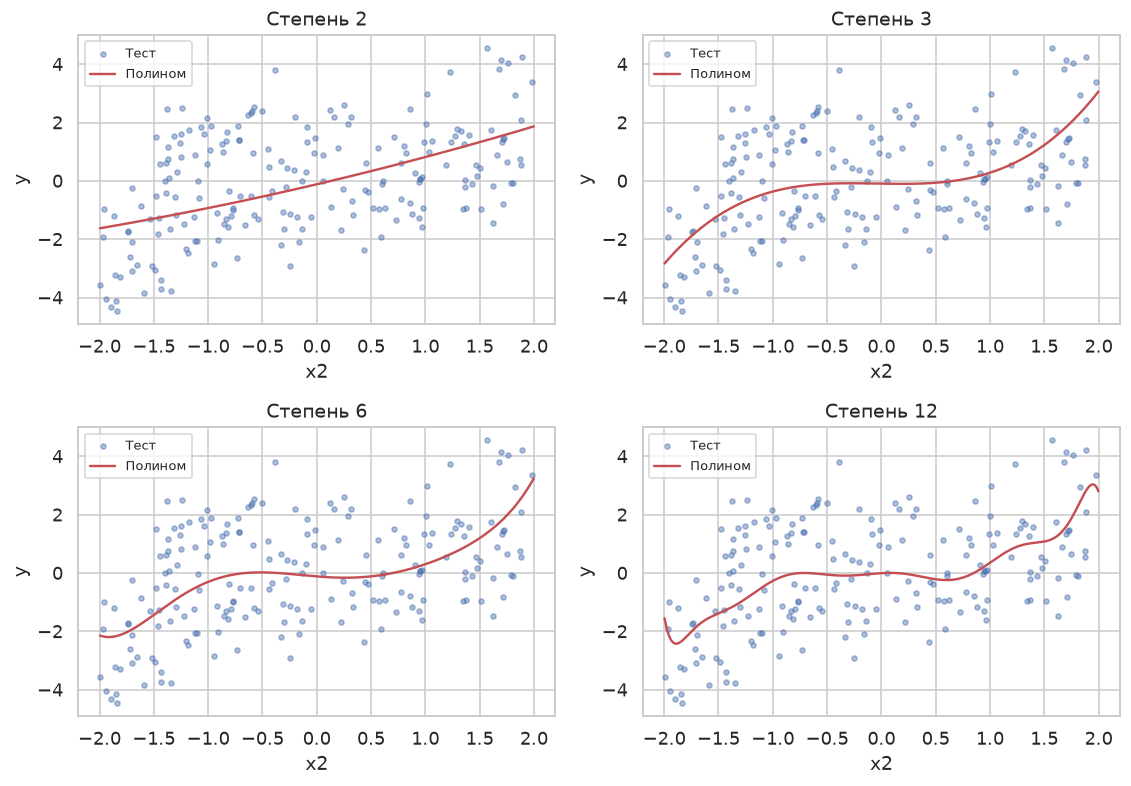

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
poly_models, poly_rows = {}, []
for degree in [1, 2, 3, 6, 12]:
    model = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False),
                          StandardScaler(), LinearRegression())
    scores = cross_val_score(model, train[['x2']], train.y, cv=cv, scoring='r2')
    model.fit(train[['x2']], train.y)
    poly_models[degree] = model
    poly_rows.append({'degree': degree, 'CV_R2': scores.mean(), 'CV_SE': scores.std(ddof=1)/np.sqrt(5),
                     'R2_train': r2_score(train.y, model.predict(train[['x2']])),
                     'R2_test': r2_score(test.y, model.predict(test[['x2']])),
                     'MAE_train': mean_absolute_error(train.y, model.predict(train[['x2']])),
                     'MAE_test': mean_absolute_error(test.y, model.predict(test[['x2']]))})
poly_metrics = pd.DataFrame(poly_rows).set_index('degree')
best_cv_degree = poly_metrics.CV_R2.idxmax()
threshold = poly_metrics.loc[best_cv_degree, 'CV_R2'] - poly_metrics.loc[best_cv_degree, 'CV_SE']
chosen_degree = int(poly_metrics[poly_metrics.CV_R2 >= threshold].index.min())
print('Выбранная степень по правилу одной стандартной ошибки:', chosen_degree)
display(poly_metrics)
poly_metrics.to_csv(OUT / 'polynomial_metrics.csv')
table_image(poly_metrics.drop(columns='CV_SE'), '09_poly_metrics')
poly_predictions = pd.DataFrame({'y_true': test.y, 'y_pred': poly_models[chosen_degree].predict(test[['x2']])}).sort_index()
poly_predictions['pred_minus_true'] = poly_predictions.y_pred - poly_predictions.y_true
display(poly_predictions)
poly_predictions.to_csv(OUT / 'predictions_polynomial.csv', index_label='row')
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
grid = pd.DataFrame({'x2': np.linspace(df.x2.min(), df.x2.max(), 500)})
for ax, degree in zip(axes.flat, [2, 3, 6, 12]):
    ax.scatter(test.x2, test.y, s=10, alpha=.45, label='Тест')
    ax.plot(grid.x2, poly_models[degree].predict(grid), 'r', label='Полином')
    ax.set(xlabel='x2', ylabel='y', title=f'Степень {degree}'); ax.legend(fontsize=8)
save('10_polynomial_lines')

Слишком низкая степень не описывает форму зависимости — возникает недообучение. Слишком высокая степень способна подстраиваться под шум, увеличивать колебания на границах и разрыв между train и test. Рост train R² сам по себе не доказывает улучшение. В данном варианте кубическая модель даёт более содержательное описание x2, а заметная оставшаяся ошибка объясняется в том числе отсутствием x1 в парной модели.

## 3 Прогнозирование годовой зарплаты
### 3.1 Данные и целевая переменная
Цель — `salary`, годовая зарплата. Предикторы: age — возраст; income — предыдущий доход; experience — опыт; score_test — результат теста; hours_worked — часы работы в неделю; distance_to_work — расстояние до работы; savings — сбережения; debt — долги; education — образование; city — город; job_type — сфера работы; marital_status — семейное положение; car — наличие машины; remote_work — удалённая работа. Денежные показатели рассматриваются в единицах исходного набора.

Пропуски и дубликаты проверяются явно. Отрицательный income трактуется как некорректный доход и заменяется пропуском; медиана для заполнения вычисляется только на train. Значения score_test выше 100 не обрезаются: шкала теста в описании не задана.

Размер: (1500, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1500 non-null   int64  
 1   income            1500 non-null   float64
 2   experience        1500 non-null   int64  
 3   score_test        1500 non-null   float64
 4   hours_worked      1500 non-null   int64  
 5   distance_to_work  1500 non-null   float64
 6   savings           1500 non-null   float64
 7   debt              1500 non-null   float64
 8   education         1500 non-null   object 
 9   city              1500 non-null   object 
 10  job_type          1500 non-null   object 
 11  marital_status    1500 non-null   object 
 12  car               1500 non-null   object 
 13  remote_work       1500 non-null   object 
 14  salary            1500 non-null   float64
dtypes: float64(6), int64(3), object(6)
memory usage: 175.9+ KB


,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education,city,job_type,marital_status,car,remote_work,salary
0,56,70201.189680,25,87.559729,62,3.708690,25987.334048,2556.821627,PhD,Chicago,Finance,Single,Yes,Yes,106233.833479
1,69,51901.897395,39,70.808381,36,7.082793,22134.899021,725.180513,High School,Houston,Retail,Single,No,Yes,87205.291042
2,46,38605.409293,4,63.324996,77,5.129154,47106.068408,12659.359583,PhD,Los Angeles,Finance,Married,Yes,No,69369.283522
3,32,49949.736955,20,78.215505,33,19.315623,15868.328813,12369.776003,Bachelor,Los Angeles,IT,Married,Yes,No,76587.116955
4,60,48965.290095,13,74.429096,48,5.654904,15734.633332,4792.095213,Bachelor,Phoenix,IT,Married,No,No,71023.148842
5,25,11326.768555,3,73.022827,39,4.879219,11916.744037,6431.835876,Bachelor,Los Angeles,IT,Single,No,Yes,49665.609629
6,38,41579.497114,22,87.163120,49,11.706144,33558.588986,12271.330484,PhD,Chicago,Retail,Single,No,Yes,92451.866841
7,56,54713.055994,19,76.671392,38,9.224122,32785.043710,4876.906464,Bachelor,New York,Retail,Single,Yes,Yes,77558.755600
8,36,43636.766522,14,77.635691,72,1.134451,40287.795615,5796.929279,Master,Phoenix,Healthcare,Married,Yes,No,70917.649089
9,40,40306.859573,28,71.729474,58,7.096197,9083.212469,12941.384435,Master,New York,IT,Married,No,No,83196.215231


,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,salary
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,43.732000,50493.562171,19.479333,74.649867,49.046000,10.169171,19920.723043,7656.749308,98573.093521
std,15.071771,15354.495706,11.471529,9.904426,17.053654,10.003094,13635.530107,5481.390395,111786.756001
min,18.000000,-826.421240,0.000000,41.604998,20.000000,0.018137,408.482014,4.367130,28588.984258
25%,31.000000,40525.989722,10.000000,67.776127,34.000000,3.022163,9418.707911,3138.484219,69582.654903
50%,44.000000,50784.690569,19.000000,74.701567,49.000000,7.105165,17114.512522,6786.703775,80310.412797
75%,56.000000,61104.997961,29.000000,81.635633,63.000000,14.392065,27766.214001,11008.309571,91637.052601
max,69.000000,98819.709397,39.000000,107.261317,79.000000,82.597342,101890.570518,27276.705593,985625.114794


Пропуски: 0 Дубликаты: 0
Отрицательный income: 1
score_test > 100: 11
Опыт больше возраста: 152


education         4
city              5
job_type          5
marital_status    3
car               2
remote_work       2
dtype: int64

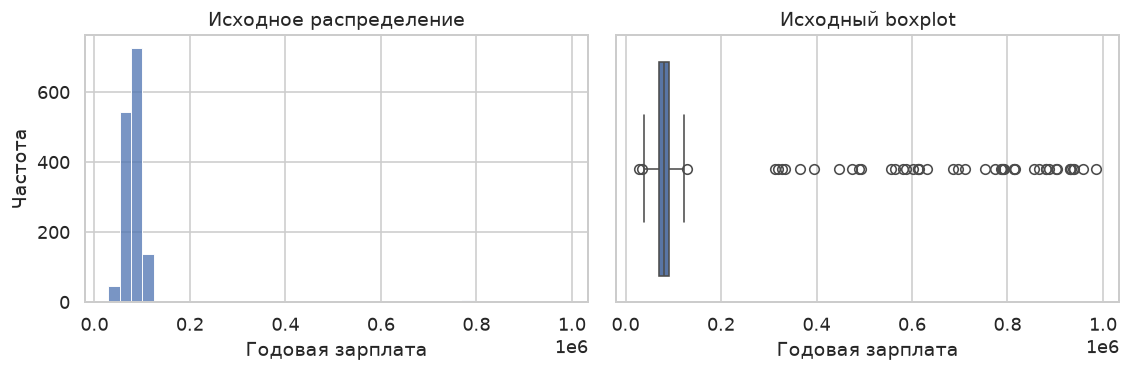

In [6]:
salary = pd.read_csv('salary.csv')
print('Размер:', salary.shape)
salary.info()
display(salary.head(10))
display(salary.describe())
print('Пропуски:', salary.isna().sum().sum(), 'Дубликаты:', salary.duplicated().sum())
print('Отрицательный income:', (salary.income < 0).sum())
print('score_test > 100:', (salary.score_test > 100).sum())
print('Опыт больше возраста:', (salary.experience > salary.age).sum())
display(salary.select_dtypes('object').nunique())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
sns.histplot(salary.salary, bins=40, ax=axes[0]); axes[0].set(xlabel='Годовая зарплата', ylabel='Частота', title='Исходное распределение')
sns.boxplot(x=salary.salary, ax=axes[1]); axes[1].set(xlabel='Годовая зарплата', title='Исходный boxplot')
save('11_salary_raw')

### 3.2 Выбросы и разделение данных
Сначала выполняется разделение 80/20. Затем границы IQR для зарплаты вычисляются **только по train**: [Q1 − 1,5 IQR; Q3 + 1,5 IQR]. Основное сравнение посвящено сотрудникам с зарплатой внутри этих границ. И обучающая, и тестовая подвыборки ограничиваются одними и теми же границами, установленными по train.

Такое ограничение меняет область задачи: результаты основного сравнения относятся только к центральному диапазону зарплат. Для прозрачности дополнительно оцениваем те же модели на **всём исходном тесте**, включая экстремальные зарплаты. Значения за IQR не объявляются ошибками без предметной проверки. Ограничение теста по известной зарплате применимо для исследования подгруппы, но не является правилом отбора клиентов при реальном прогнозировании.

### Формулы IQR и графиков распределения

Квартили целевой переменной вычисляются только по исходному train зарплаты. Границы центральной подгруппы фиксируются один раз и затем применяются к train и test:

$$
Q_1=Q_{0.25}(y_{tr});\quad Q_3=Q_{0.75}(y_{tr});\quad IQR=Q_3-Q_1
$$

$$
L=Q_1-1.5\,IQR;\quad U=Q_3+1.5\,IQR
$$

$$
D_{core}=\{(x_i,y_i)\in D:L\leq y_i\leq U\}
$$

D означает train или test; pandas.between включает обе границы. Ограничение теста по известной зарплате описывает подгруппу и не задаёт способ отбора новых сотрудников при неизвестной цели. Полный test оценивается отдельно.

Гистограмма показывает число значений внутри интервала Bᵦ. Индикатор 1[условие] равен 1 при выполнении условия и 0 иначе:

$$
H_b=\sum_{i=1}^{n}\mathbf{1}[y_i\in B_b]
$$

В boxplot коробка ограничена Q₁ и Q₃, линия внутри — медиана. Усы заканчиваются на крайних наблюдаемых значениях внутри собственных границ IQR изображаемой выборки:

$$
W_{low}=\min\{y_i:y_i\geq Q_1-1.5\,IQR\};\quad W_{high}=\max\{y_i:y_i\leq Q_3+1.5\,IQR\}
$$

Точки за усами показываются отдельно. Для графика после ограничения квартили пересчитываются по отображаемым данным, поэтому новые точки за усами возможны. Диаграммы рассеяния и матрица pairplot отображают пары наблюдений (xᵢ, yᵢ), не добавляя отдельного метода обучения.


Q1=69357.29; Q3=91142.05; IQR=21784.75; границы=[36680.16; 123819.18]
Train до/после: 1200 1162
Test до/после: 300 290


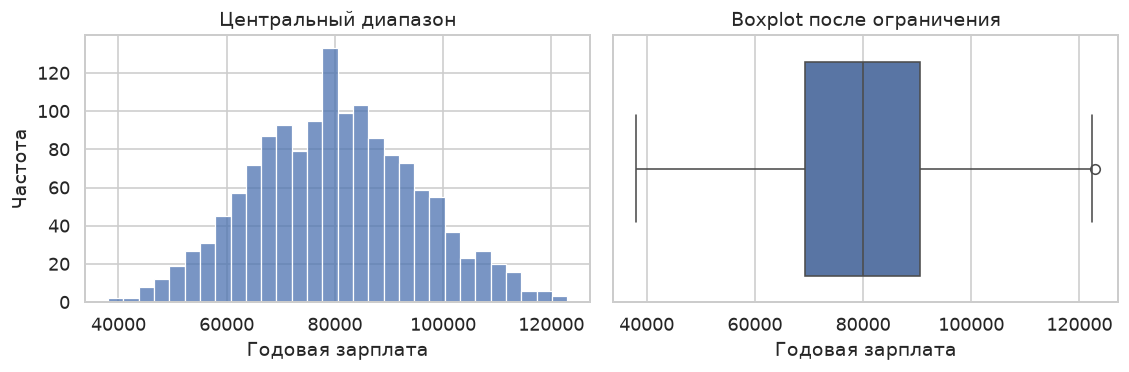

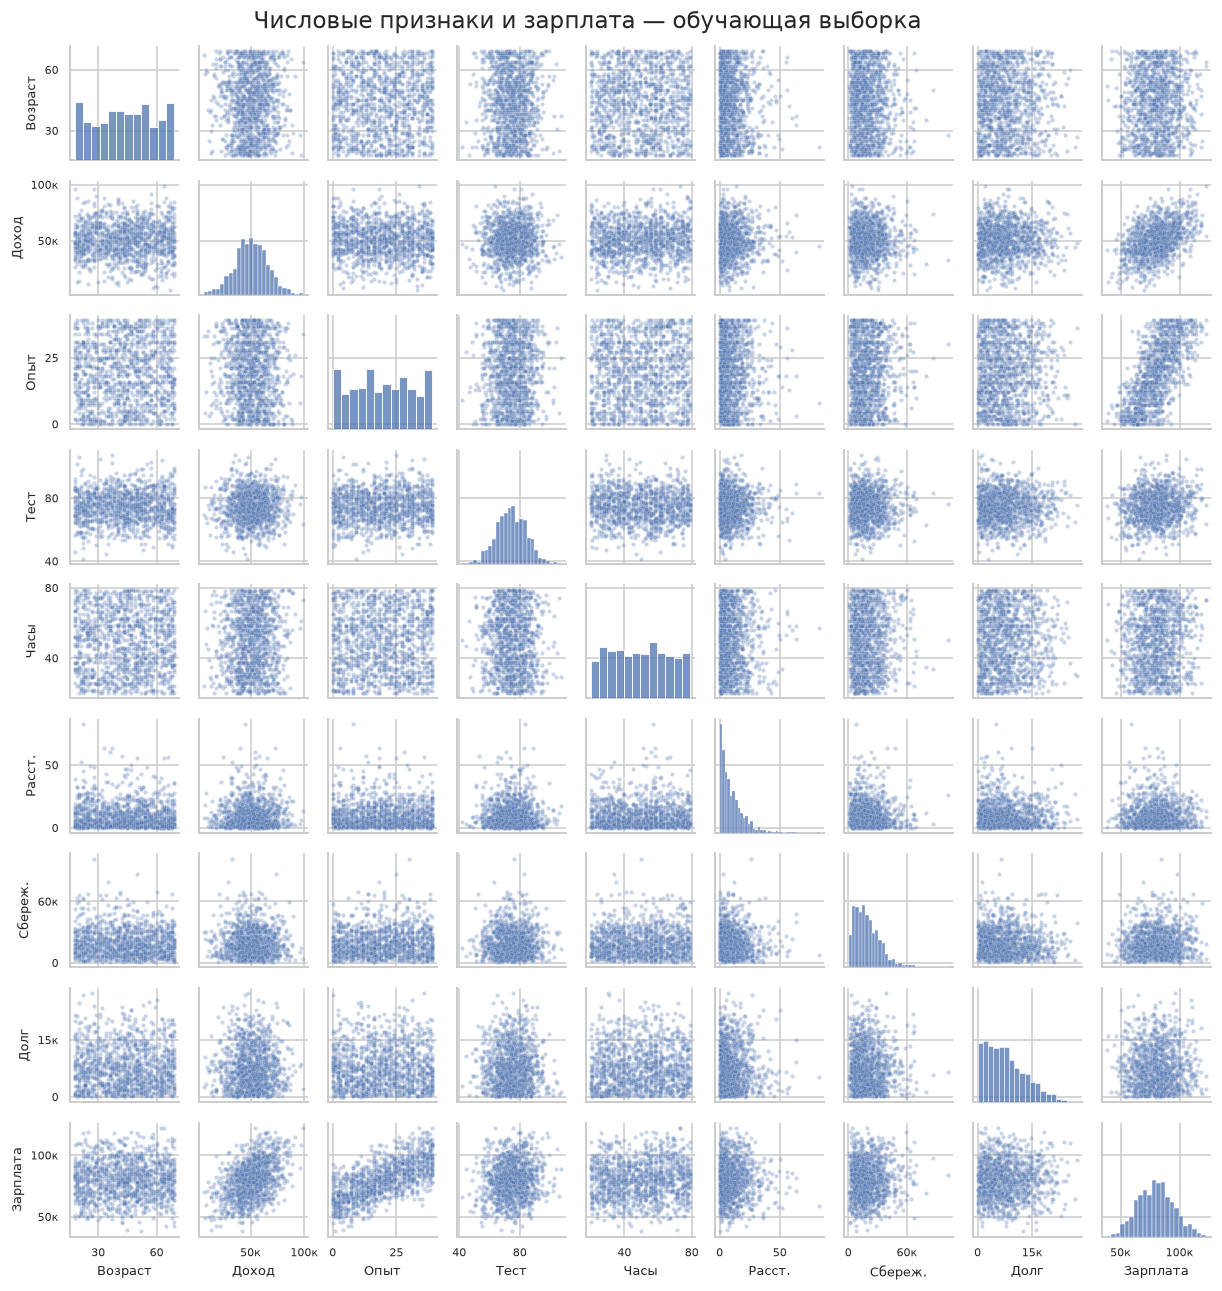

In [7]:
salary = salary.drop_duplicates().copy()
salary.loc[salary.income < 0, 'income'] = np.nan
s_train, s_test_full = train_test_split(salary, test_size=.2, random_state=SEED)
q1, q3 = s_train.salary.quantile([.25, .75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
s_train_core = s_train[s_train.salary.between(lower, upper)].copy()
s_test = s_test_full[s_test_full.salary.between(lower, upper)].copy()
print(f'Q1={q1:.2f}; Q3={q3:.2f}; IQR={iqr:.2f}; границы=[{lower:.2f}; {upper:.2f}]')
print('Train до/после:', len(s_train), len(s_train_core))
print('Test до/после:', len(s_test_full), len(s_test))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
core_plot = pd.concat([s_train_core, s_test])
sns.histplot(core_plot.salary, bins=30, ax=axes[0]); axes[0].set(xlabel='Годовая зарплата', ylabel='Частота', title='Центральный диапазон')
sns.boxplot(x=core_plot.salary, ax=axes[1]); axes[1].set(xlabel='Годовая зарплата', title='Boxplot после ограничения')
save('12_salary_core')
# Матрица строится по train, чтобы изучение test не влияло на выбор модели.
pair_data = s_train_core.select_dtypes('number').rename(columns={
    'age':'Возраст', 'income':'Доход', 'experience':'Опыт', 'score_test':'Тест',
    'hours_worked':'Часы', 'distance_to_work':'Расст.', 'savings':'Сбереж.',
    'debt':'Долг', 'salary':'Зарплата'})
pair = sns.pairplot(pair_data, diag_kind='hist',
                    plot_kws={'s': 7, 'alpha': .3}, height=1.25)
from matplotlib.ticker import MaxNLocator, FuncFormatter
short_tick = FuncFormatter(lambda v, p: f'{v/1000:g}к' if abs(v) >= 1000 else f'{v:g}')
for ax in pair.axes.flat:
    ax.tick_params(axis='both', labelsize=7, pad=1)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=2))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=2))
    ax.xaxis.set_major_formatter(short_tick)
    ax.yaxis.set_major_formatter(short_tick)
    ax.xaxis.label.set_size(8); ax.yaxis.label.set_size(8)
pair.fig.subplots_adjust(wspace=.18, hspace=.18)
pair.fig.suptitle('Числовые признаки и зарплата — обучающая выборка', y=1.01)
pair.savefig(OUT / '13_pairplot.png', dpi=170, bbox_inches='tight'); plt.show()

### 3.3 Кодирование и масштабирование
Числовые признаки заполняются медианами и стандартизируются. Категориальные признаки заполняются модой и кодируются OneHotEncoder с удалением первой категории и обработкой новых категорий. `salary` исключён из X. Pipeline обучает все преобразования только на train.

Используется фиксированная базовая конфигурация: kNN с 5 соседями, дерево глубины 6 с минимумом 10 объектов в листе. Гиперпараметры по тесту не подбираются. Также используется прогноз средним как базовый ориентир.

### Формулы заполнения и преобразования признаков

Для числового столбца j медиана mⱼ вычисляется по непустым обучающим значениям; Oⱼ — множество индексов этих значений в train. Если значение отсутствует, оно заменяется mⱼ; иначе сохраняется. В коде отрицательный income сначала переводится в пропуск. Для категориального столбца используется наиболее частая категория:

$$
m_j=\operatorname{median}(x_{ij}:i\in O_j)
$$

$$
c_j^*=\operatorname{argmax}_{c}\sum_{i\in train}\mathbf{1}[x_{ij}=c]
$$

Обозначим заполненные значения через x̃ᵢⱼ. Среднее и дисперсия StandardScaler вычисляются после заполнения по train. Здесь делитель nₜᵣ (ddof = 0), в отличие от std в pandas.describe():

$$
\mu_j=\frac{1}{n_{tr}}\sum_{i=1}^{n_{tr}}\tilde{x}_{ij};\quad s_j=\sqrt{\frac{1}{n_{tr}}\sum_{i=1}^{n_{tr}}(\tilde{x}_{ij}-\mu_j)^2}
$$

$$
z_{ij}=\frac{\tilde{x}_{ij}-\mu_j}{s_j}
$$

При нулевой дисперсии StandardScaler использует масштаб 1. На test применяются те же mⱼ, μⱼ и sⱼ. Полиномиальные столбцы масштабируются по той же формуле. Категория c₀ удаляется как базовая; для остальных категорий создаются индикаторы:

$$
d_{ic}=\mathbf{1}[x_{ij}=c];\quad c\ne c_0
$$

При базовой категории все её индикаторы равны 0. Неизвестная категория при handle_unknown="ignore" также даёт нули в блоке соответствующего столбца. Итоговый вектор u содержит восемь стандартизированных числовых признаков и пятнадцать индикаторов, всего 23 компоненты.


### Формулы моделей прогнозирования зарплаты

Пусть u — итоговый преобразованный вектор, p = 23. Множественная линейная регрессия и критерий обучения:

$$
\hat{y}(u)=b+\sum_{j=1}^{p}w_j u_j
$$

$$
(b,w)=\operatorname{argmin}_{b,w}\sum_{i=1}^{n_{tr}}(y_i-b-\sum_{j=1}^{p}w_j u_{ij})^2
$$

В матричной форме θ = A⁺y, где A — матрица train с добавленным столбцом единиц, θ содержит свободный член и коэффициенты, A⁺ — псевдообратная матрица. Это математическая запись решения МНК; библиотека решает задачу численно без явного обращения AᵀA.

KNeighborsRegressor использует евклидово расстояние в том же преобразованном пространстве. Прогноз — невзвешенное среднее зарплат k = 5 ближайших обучающих объектов:

$$
d(u,v)=\sqrt{\sum_{j=1}^{p}(u_j-v_j)^2};\quad \hat{y}(u)=\frac{1}{k}\sum_{i\in N_k(u)}y_i;\quad k=5
$$

Nₖ(u) — множество индексов ближайших соседей. Для дерева с критерием squared_error прогноз в листе R — среднее y обучающих объектов листа; нечистота — средний квадрат отклонения от этого среднего:

$$
\bar{y}_R=\frac{1}{n_R}\sum_{i\in R}y_i;\quad I(R)=\frac{1}{n_R}\sum_{i\in R}(y_i-\bar{y}_R)^2;\quad \hat{y}(u)=\bar{y}_{R(u)}
$$

При разделении по признаку j и порогу t дерево сравнивает взвешенную нечистоту дочерних узлов и выбирает допустимое разделение с наибольшим уменьшением:

$$
R_L=\{i\in R:u_{ij}\leq t\};\quad R_R=\{i\in R:u_{ij}>t\}
$$

$$
\Delta I=I(R)-\frac{|R_L|}{|R|}I(R_L)-\frac{|R_R|}{|R|}I(R_R)
$$

Здесь |R|, |R_L| и |R_R| — число объектов родительского, левого и правого узлов. Для выбора разделения в фиксированном узле множитель его доли в общей обучающей выборке не меняет максимум. Глубина ограничена 6, каждый лист должен содержать минимум 10 обучающих объектов. Постоянный базовый прогноз DummyRegressor равен среднему целевой переменной train:

$$
\hat{y}_{base}(u)=\bar{y}_{tr}=\frac{1}{n_{tr}}\sum_{i=1}^{n_{tr}}y_i
$$

Все модели проверяются одними и теми же четырьмя метриками. Метрики полного теста отличаются от метрик центральной подгруппы из-за состава оцениваемых строк, а не из-за переобучения модели между этими оценками.


,R2_train,MSE,MAE,RMSE,R2
Модель,,,,,
Среднее,0.000000,2.482867e+08,12616.923739,15757.115907,-0.003203
Линейная,0.852907,4.008277e+07,5022.730402,6331.095472,0.838045
kNN,0.750675,1.104167e+08,8373.993551,10507.936846,0.553861
Дерево,0.775042,7.262975e+07,6754.650414,8522.308812,0.706539


,MSE,MAE,RMSE,R2
Модель,,,,
Среднее,1.419557e+10,31956.329987,119145.148820,-0.030879
Линейная,1.409061e+10,24602.819991,118703.884770,-0.023257
kNN,1.416007e+10,27860.632872,118996.083304,-0.028301
Дерево,1.397711e+10,26161.848555,118224.811467,-0.015014


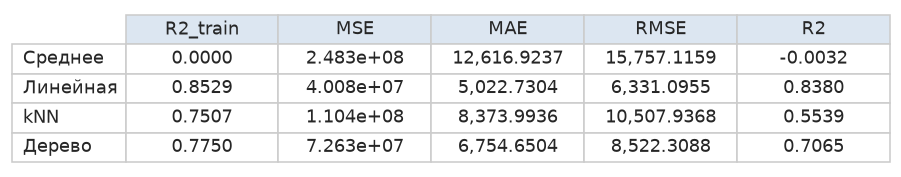

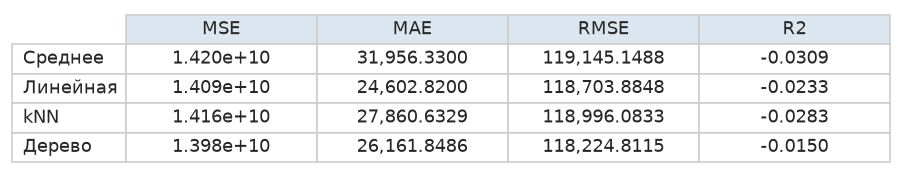

,y_true,Среднее,Линейная,kNN,Дерево,error_Среднее,error_Линейная,error_kNN,error_Дерево
15,63876.307670,79940.358586,68421.819491,74704.157517,68796.464455,16064.050916,4545.511821,10827.849847,4920.156785
23,111198.257761,79940.358586,119888.425187,103395.923019,111219.248335,-31257.899175,8690.167426,-7802.334742,20.990574
29,44219.056055,79940.358586,60647.510552,71389.417178,58936.769528,35721.302531,16428.454497,27170.361123,14717.713473
30,90837.188701,79940.358586,74164.803946,71133.471086,58936.769528,-10896.830115,-16672.384755,-19703.717615,-31900.419173
32,91766.966835,79940.358586,87585.552637,82399.361249,82267.817384,-11826.608249,-4181.414198,-9367.605586,-9499.149451
43,89125.427373,79940.358586,89351.490313,88540.859579,93285.220157,-9185.068787,226.062940,-584.567795,4159.792784
44,71288.910020,79940.358586,66670.043603,75714.304939,78666.148451,8651.448566,-4618.866417,4425.394918,7377.238431
49,83843.268389,79940.358586,80480.855886,82788.081566,80909.004624,-3902.909803,-3362.412502,-1055.186823,-2934.263765
51,92644.349266,79940.358586,89068.814849,85684.826033,86722.273133,-12703.990680,-3575.534417,-6959.523233,-5922.076133
56,101768.078051,79940.358586,105907.631342,99590.695654,105056.121734,-21827.719465,4139.553290,-2177.382397,3288.043683


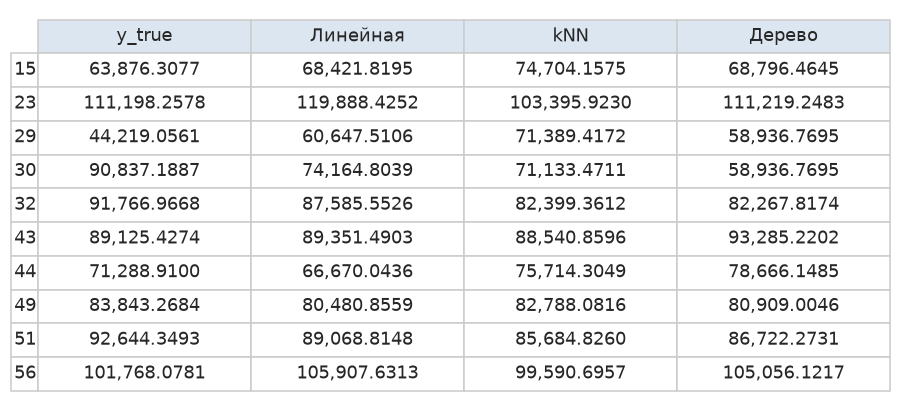

In [8]:
X_train, y_train = s_train_core.drop(columns='salary'), s_train_core.salary
X_test, y_test = s_test.drop(columns='salary'), s_test.salary
X_full, y_full = s_test_full.drop(columns='salary'), s_test_full.salary
num_cols = X_train.select_dtypes('number').columns.tolist()
cat_cols = X_train.select_dtypes('object').columns.tolist()

def preprocessor():
    return ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_cols),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                              OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)), cat_cols)
    ])
models = {
    'Среднее': DummyRegressor(strategy='mean'),
    'Линейная': LinearRegression(),
    'kNN': KNeighborsRegressor(n_neighbors=5),
    'Дерево': DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=SEED)
}
fitted, salary_rows, full_rows, salary_predictions = {}, [], [], pd.DataFrame({'y_true': y_test})
for name, estimator in models.items():
    pipe = Pipeline([('prep', preprocessor()), ('model', estimator)])
    pipe.fit(X_train, y_train); fitted[name] = pipe
    salary_predictions[name] = pipe.predict(X_test)
    salary_rows.append({'Модель': name, 'R2_train': r2_score(y_train, pipe.predict(X_train)), **metrics(y_test, pipe.predict(X_test))})
    full_rows.append({'Модель': name, **metrics(y_full, pipe.predict(X_full))})
salary_metrics = pd.DataFrame(salary_rows).set_index('Модель')
full_metrics = pd.DataFrame(full_rows).set_index('Модель')
display(salary_metrics); display(full_metrics)
salary_metrics.to_csv(OUT / 'salary_metrics_core.csv'); full_metrics.to_csv(OUT / 'salary_metrics_full.csv')
table_image(salary_metrics, '14_salary_metrics')
table_image(full_metrics, '15_salary_metrics_full')
for name in models:
    salary_predictions[f'error_{name}'] = salary_predictions[name] - salary_predictions.y_true
salary_predictions = salary_predictions.sort_index()
with pd.option_context('display.max_rows', None): display(salary_predictions)
salary_predictions.to_csv(OUT / 'salary_predictions.csv', index_label='row')
table_image(salary_predictions[['y_true', 'Линейная', 'kNN', 'Дерево']].head(10), '16_salary_predictions')

### 3.4 Коэффициенты линейной модели
Для числовых переменных коэффициент показывает изменение прогноза при увеличении признака на одно стандартное отклонение train при остальных фиксированных признаках. Для категорий коэффициент показывает отличие от базовой категории. Эти величины полезны для описания модели, но их модули не являются универсальной мерой важности и не доказывают причинное влияние.

### Формулы интерпретации коэффициентов

Увеличение числового признака j на одно обучающее стандартное отклонение при остальных фиксированных признаках увеличивает прогноз на wⱼ. Для изменения на Δxⱼ в исходных единицах и перехода от базовой категории к c:

$$
\Delta\hat{y}=\frac{w_j}{s_j}\Delta x_j;\quad \Delta\hat{y}_{c:c_0}=w_c
$$

Сортировка коэффициентов в коде производится по модулю |wⱼ|. Линейная модель имеет также свободный член b. Коэффициенты описывают условные связи этой модели, не доказывают причинность и не дают универсальной шкалы важности при сравнении числовых и категориальных признаков.


Свободный член: 76258.19861489713
Базовые категории: {'education': 'Bachelor', 'city': 'Chicago', 'job_type': 'Education', 'marital_status': 'Divorced', 'car': 'No', 'remote_work': 'No'}


,Признак,Коэффициент,Модуль
10,cat__education_PhD,11967.947189,11967.947189
2,num__experience,10465.068652,10465.068652
1,num__income,7204.930687,7204.930687
9,cat__education_Master,6312.063707,6312.063707
8,cat__education_High School,-6235.982685,6235.982685
17,cat__job_type_IT,4315.197507,4315.197507
15,cat__job_type_Finance,2453.880115,2453.880115
13,cat__city_New York,1605.595408,1605.595408
3,num__score_test,1313.615576,1313.615576
14,cat__city_Phoenix,1276.448493,1276.448493


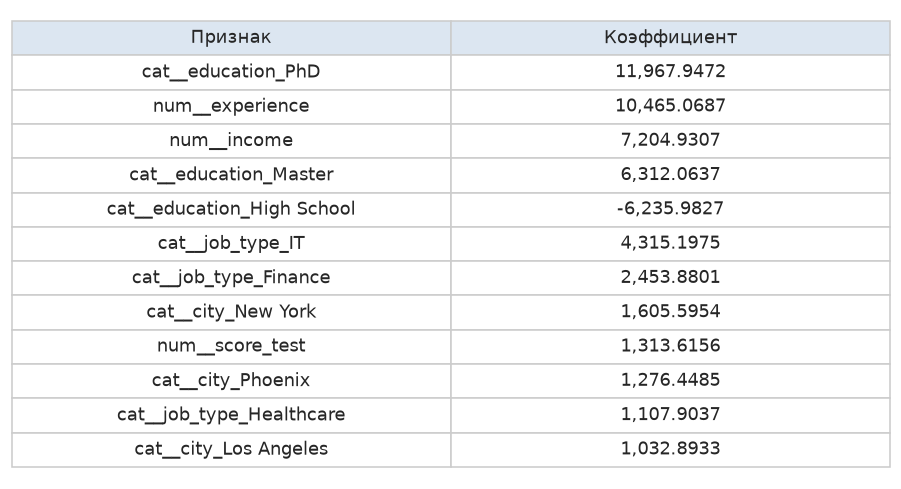

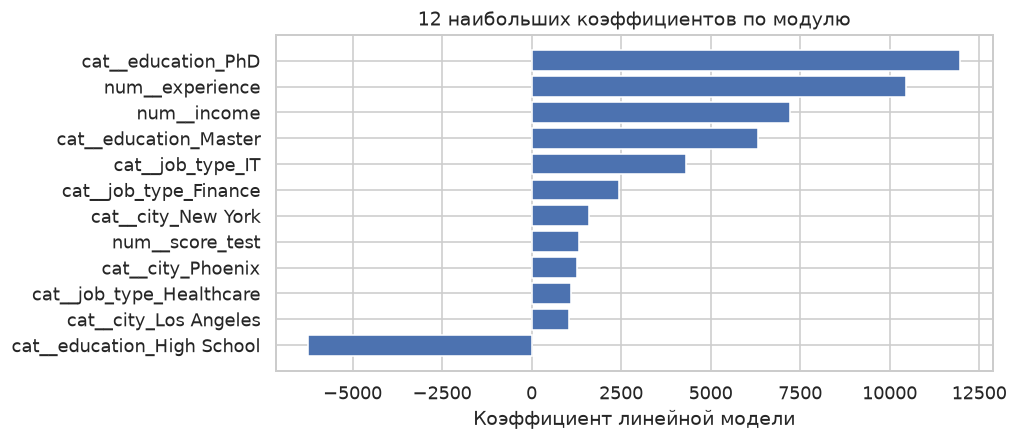

In [9]:
linear = fitted['Линейная']
feature_names = linear.named_steps['prep'].get_feature_names_out()
coefficients = pd.DataFrame({'Признак': feature_names, 'Коэффициент': linear.named_steps['model'].coef_})
coefficients['Модуль'] = coefficients['Коэффициент'].abs()
coefficients = coefficients.sort_values('Модуль', ascending=False)
print('Свободный член:', linear.named_steps['model'].intercept_)
encoder = linear.named_steps['prep'].named_transformers_['cat'].named_steps['onehotencoder']
print('Базовые категории:', dict(zip(cat_cols, [c[0] for c in encoder.categories_])))
display(coefficients)
coefficients.to_csv(OUT / 'salary_coefficients.csv', index=False)
table_image(coefficients.drop(columns='Модуль').head(12), '17_coefficients', index=False)
fig, ax = plt.subplots(figsize=(9, 4))
plot_coef = coefficients.head(12).sort_values('Коэффициент')
ax.barh(plot_coef.Признак, plot_coef.Коэффициент); ax.set(xlabel='Коэффициент линейной модели', title='12 наибольших коэффициентов по модулю')
save('18_coefficients_plot')

### 3.5 Сравнение фактических значений и прогнозов
Сравниваем модели на одних и тех же объектах центрального теста. В идеальной модели точки лежат на диагонали; при сопоставлении последовательностей порядок выбран по истинной зарплате только для удобства отображения.

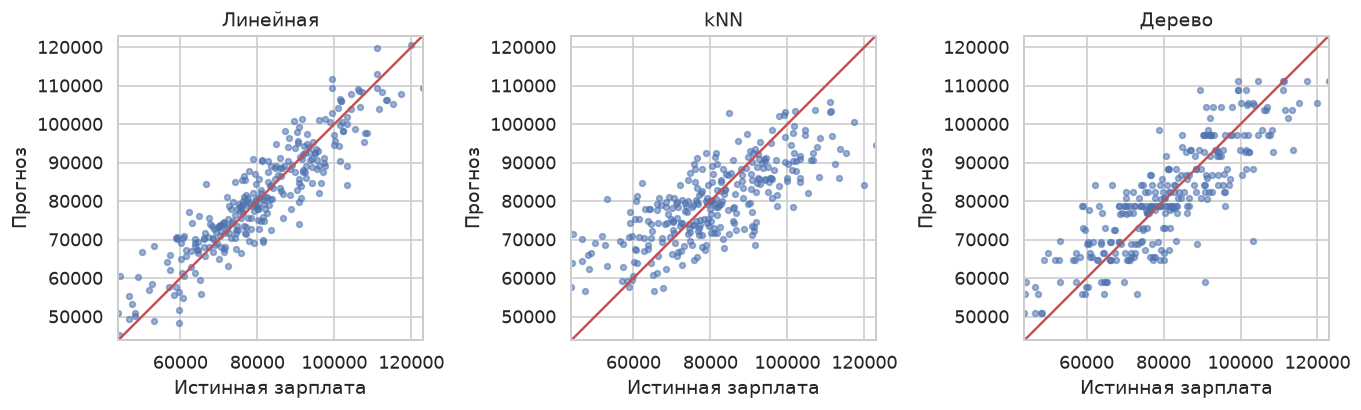

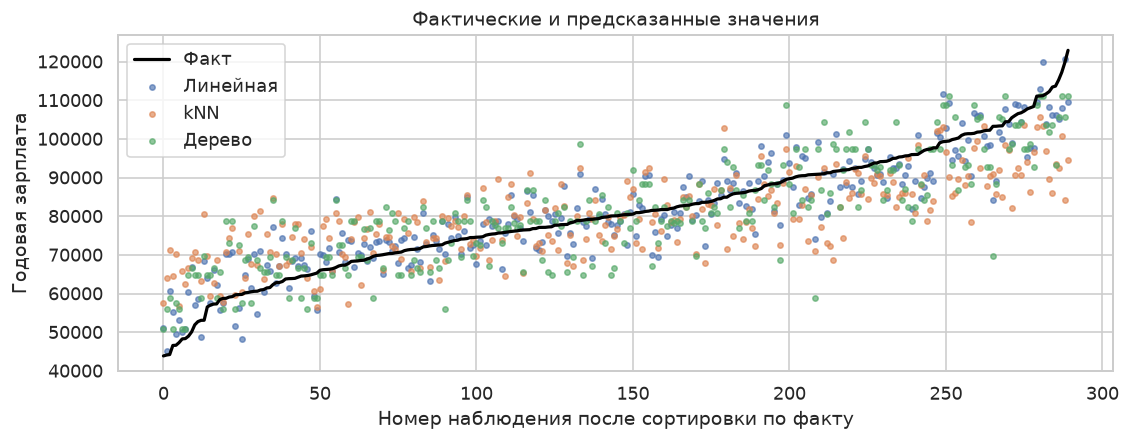

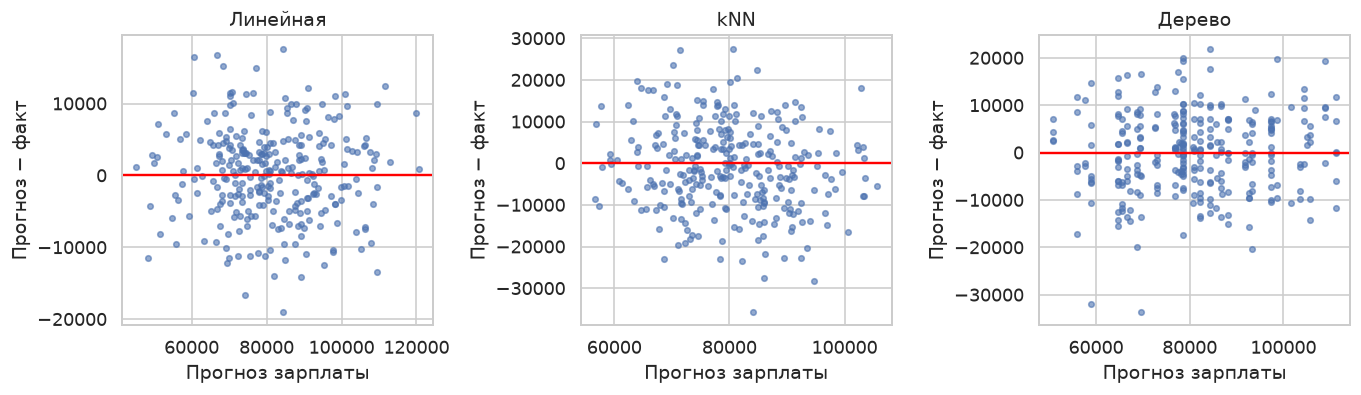

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
lo = min(y_test.min(), salary_predictions[['Линейная','kNN','Дерево']].min().min())
hi = max(y_test.max(), salary_predictions[['Линейная','kNN','Дерево']].max().max())
for ax, name in zip(axes, ['Линейная', 'kNN', 'Дерево']):
    ax.scatter(y_test, fitted[name].predict(X_test), s=13, alpha=.55)
    ax.plot([lo,hi], [lo,hi], 'r'); ax.set(xlabel='Истинная зарплата', ylabel='Прогноз', title=name, xlim=(lo,hi), ylim=(lo,hi)); ax.set_aspect('equal')
save('19_salary_actual')
ordered = salary_predictions.sort_values('y_true').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ordered.y_true, color='black', linewidth=2, label='Факт')
for name in ['Линейная', 'kNN', 'Дерево']:
    ax.scatter(ordered.index, ordered[name], s=11, alpha=.65, label=name)
ax.set(xlabel='Номер наблюдения после сортировки по факту', ylabel='Годовая зарплата', title='Фактические и предсказанные значения'); ax.legend()
save('20_salary_comparison')
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, name in zip(axes, ['Линейная', 'kNN', 'Дерево']):
    pred = fitted[name].predict(X_test)
    ax.scatter(pred, pred-y_test, s=12, alpha=.6); ax.axhline(0,color='red')
    ax.set(xlabel='Прогноз зарплаты', ylabel='Прогноз − факт', title=name)
save('21_salary_residuals')

## Выводы
Выводы ниже сформированы по выполненным расчётам. Основные ограничения: одна фиксированная тестовая выборка, синтетические и потенциально несогласованные признаки сотрудников, а также ограничение основного сравнения центральным диапазоном зарплат. Результаты не устанавливают причинных связей.

In [11]:
best_salary = salary_metrics.R2.idxmax()
summary = {
 'chosen_degree': chosen_degree, 'best_salary': best_salary,
 'salary_shape': list(salary.shape), 'salary_lower': float(lower), 'salary_upper': float(upper),
 'q1': float(q1), 'q3': float(q3),
 'train_raw': len(s_train), 'train_core': len(s_train_core),
 'test_raw': len(s_test_full), 'test_core': len(s_test),
 'salary_intercept': float(linear.named_steps['model'].intercept_),
 'baselines': dict(zip(cat_cols, [str(c[0]) for c in encoder.categories_]))
}
(OUT / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2))
print('Парные модели:')
display(linear_metrics[['MAE','RMSE','R2']])
print('Полиномиальная модель, выбранная по CV:')
display(poly_metrics.loc[[chosen_degree]])
print('Лучшая модель зарплаты в центральном диапазоне:', best_salary)
print('Её качество в центральном диапазоне:'); display(salary_metrics.loc[[best_salary]])
print('Её качество на полном тесте:'); display(full_metrics.loc[[best_salary]])
import sklearn, matplotlib, sys
print('Версии:', 'Python', sys.version.split()[0], 'pandas', pd.__version__,
      'numpy', np.__version__, 'sklearn', sklearn.__version__, 'matplotlib', matplotlib.__version__)

Парные модели:


,MAE,RMSE,R2
Признак,,,
x1,0.949193,1.249017,0.542221
x2,1.379719,1.656449,0.194854


Полиномиальная модель, выбранная по CV:


,CV_R2,CV_SE,R2_train,R2_test,MAE_train,MAE_test
degree,,,,,,
3,0.308568,0.015821,0.328482,0.283506,1.348642,1.328753


Лучшая модель зарплаты в центральном диапазоне: Линейная
Её качество в центральном диапазоне:


,R2_train,MSE,MAE,RMSE,R2
Модель,,,,,
Линейная,0.852907,4.008277e+07,5022.730402,6331.095472,0.838045


Её качество на полном тесте:


,MSE,MAE,RMSE,R2
Модель,,,,
Линейная,1.409061e+10,24602.819991,118703.88477,-0.023257


Версии: Python 3.12.14 pandas 2.2.3 numpy 2.3.5 sklearn 1.9.1 matplotlib 3.11.2


### Итоги выполненного эксперимента
На тесте парная модель **x1** получила R² = **0,5422**, MAE = **0,9492**; модель **x2** — R² = **0,1949**, MAE = **1,3797**. Для x2 кросс-валидация выбрала **степень 3**, тестовый R² вырос до **0,2835**, MAE снизилась до **1,3288**. Увеличение степени до 6 и 12 не улучшило средний CV R².

В salary.csv границы IQR по train равны **36 680,16–123 819,18**. В центральном диапазоне осталось **1162 train** и **290 test**. Линейная регрессия дала лучшие тестовые результаты: **R² = 0,8380, MAE = 5022,73, RMSE = 6331,10**. У дерева R² = 0,7065, у kNN — 0,5539. Наиболее выраженные числовые коэффициенты относятся к опыту и предыдущему доходу, а категориальные — к образованию.

На **полном тесте из 300 строк** линейная модель получила **R² = −0,0233**, MAE = 24 602,82: редкие высокие зарплаты она не прогнозирует достаточно точно. Результат центрального диапазона нельзя переносить на весь набор. Для поставленной задачи внутри центрального диапазона предпочтительна линейная регрессия; для экстремальных значений нужна отдельная проверка данных и постановка задачи.

### Источники и воспроизведение
Методические указания «Лабораторная работа 3. Регрессионный анализ» из материалов курса; `regression.xlsx`, лист `var6`; `salary.csv`.

Выполнить **Kernel → Restart & Run All** либо **Среда выполнения → Выполнить всё** в Colab. Дополнительные задания, выдаваемые после защиты, в основной объём не включены. Полные таблицы прогнозов и метрик сохраняются в папку `results`.
